# 06c objective ablation: decoder CLM vs encoder MLM, and perplexity vs PR-AUC

One of the two groups of step 6c (the other is `06c_tokenizer.ipynb`). Both arms pretrain from scratch on this machine with the step-2 tokenizer, then fine-tune for fraud exactly as step 4 did (H = 12, last-token pooling, three seeds). The control arm A is retrained here, so the comparison is between runs of one machine (same-machine rule, see 06b). The two groups write disjoint folders (`ablate_pre/objective/`) and disjoint result files (`06c_objective_...`), so they can run on two machines at the same time.

| arm | tokenizer | objective | talk it tests |
|---|---|---|---|
| A_ref | step 2's | CLM (decoder, next token) | the control; its training also leaves snapshots for the scatter |
| D_mlm | step 2's | MLM (encoder, 15% masked) | WF (decoder wins) vs Wealthsimple (MLM for event-level anomalies) |

Validator check 1, intrinsic vs extrinsic: arm A saves the weights at five log-spaced steps of its pretraining; each snapshot is fine-tuned once (seed 0) and its perplexity is plotted against the test PR-AUC. Wealthsimple's claim is that the two correlate weakly.

**Budget.** Two pretraining runs (8 epochs, about 8,000 steps: about 37 min each on a T4, about 1.5 h on Apple MPS) plus eleven fine-tuning runs (3 seeds x 2 arms + 5 snapshots; about 10 min each on a T4, about 23 min on MPS). Everything is resumable: a disconnect loses at most one save interval, a finished arm or run is skipped by its json. Rerun the notebook from the top after a disconnect.

In [1]:
import os, sys, glob, shutil
REPO = "lb603487485/transaction-fm"                                 # on a fork: your own owner/name
try:
    from google.colab import drive, userdata                      # Colab: mount Drive, pull the repo, sync new notebooks to Drive
    drive.mount("/content/drive")
    try: tok = userdata.get("GH_TOKEN")                            # only needed to push results back; a public repo clones without it
    except Exception: tok = ""
    url = f"https://{tok}@github.com/{REPO}.git" if tok else f"https://github.com/{REPO}.git"
    if not os.path.exists("/content/transaction-fm"):
        !git clone -q {url} /content/transaction-fm
    else:
        !cd /content/transaction-fm && git pull -q
    %pip install -q datasets xgboost
    %cd /content/transaction-fm
except ImportError:                                               # laptop: this notebook is the repo copy; data under $TFM_ROOT
    here = os.getcwd()
    while not os.path.isdir(os.path.join(here, "src", "tfm")):
        assert here != os.path.dirname(here), "run this notebook from inside the transaction-fm repo"
        here = os.path.dirname(here)
    %cd {here}
sys.path.insert(0, os.path.abspath("src"))
from tfm.runtime import root, describe, on_colab
ROOT = root()
os.makedirs(f"{ROOT}/notebooks", exist_ok=True)
if on_colab():
    for f in glob.glob("notebooks/*.ipynb"):                      # new notebooks from the repo appear in Drive
        dst = f"{ROOT}/notebooks/{os.path.basename(f)}"
        if not os.path.exists(dst):
            shutil.copy(f, dst); print("new notebook in Drive:", os.path.basename(f))
import tfm
print("tfm ok |", describe(), "| ROOT =", ROOT if on_colab() else os.path.relpath(ROOT))   # laptop: relative to the repo

/Users/evolin1/Desktop/AICoding/MLProject/transaction-fm
tfm ok | {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'} | ROOT = /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm


## Stage 6c-0: the arms' tokenizers, side by side

`arm_data` fits each arm's tokenizer on train rows (through `assert_train_only`), encodes every row with it and cuts the 512-token windows for train and val, cached under the arm folder. Arms that share a tokenizer configuration still fit and store their own copy, so an arm folder is self-contained. The example row shows what changed between arms. The three dicts at the top stay empty in a real run; the smoke run on the synthetic fixture fills them to make the models tiny and the runs short.

In [2]:
import json, time, os, numpy as np, pandas as pd
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40)
from pathlib import Path
from tfm.finetune import build_examples
from tfm.metrics import mean_sd
from tfm.ablate import finetune_run, run_name
from tfm.ablate_pretrain import ARMS, GROUPS, SEEDS, arm_tokenizer_config, arm_data, pretrain_arm, finetune_spec, pretrained_dir
from tfm.runtime import accelerator

GROUP = "objective"
ARM_LIST, SNAP_ARM = GROUPS[GROUP]["arms"], GROUPS[GROUP]["snapshots"]
EPOCHS = 8                                   # the guide's pretraining length, as in step 3
PRE_OVERRIDES, FT_OVERRIDES, CFG = {}, {}, {}   # empty in a real run; the smoke run sets tiny values here
RES = f"{ROOT}/results"; os.makedirs(RES, exist_ok=True)
df = pd.read_parquet(f"{ROOT}/data/processed/transactions.parquet")
card, split, fraud = df["card_id"].to_numpy(), df["split"].to_numpy(), df["is_fraud"].to_numpy()
DEV = accelerator()
print("group:", GROUP, "arms:", ARM_LIST, "| accelerator:", DEV, describe())

toks, windows, rows = {}, {}, []
for arm in ARM_LIST:
    tok, tw, vw = arm_data(GROUP, arm, df, ROOT)
    toks[arm], windows[arm] = tok, (tw, vw)
    rows.append({"arm": arm, "objective": ARMS[arm]["objective"], **{k: v for k, v in arm_tokenizer_config(arm).items() if k in ("amt_binning", "use_dt")},
                 "vocab": len(tok.vocab), "tokens/tx": tok.tokens_per_tx, "train windows": len(tw), "val windows": len(vw),
                 "example row": " ".join(tok.decode(tw[0][:tok.tokens_per_tx]))})
display(pd.DataFrame(rows))

group: objective arms: ['A_ref', 'D_mlm'] | accelerator: mps {'where': 'laptop', 'gpu': None, 'device': 'cpu', 'accelerator': 'mps', 'fp16': False, 'machine': 'Darwin arm64 12 cores'}
A_ref: tokenizer fit on train, vocab 567, 7 tokens per transaction, 31,856 train windows, 1,407 val windows, 3 s
D_mlm: tokenizer fit on train, vocab 567, 7 tokens per transaction, 31,856 train windows, 1,407 val windows, 4 s


,arm,objective,use_dt,amt_binning,vocab,tokens/tx,train windows,val windows,example row
0,A_ref,clm,True,log,567,7,31856,1407,<TX> DT_NA HOUR_AFTERNOON CAT_misc_net MER_OTH...
1,D_mlm,mlm,True,log,567,7,31856,1407,<TX> DT_NA HOUR_AFTERNOON CAT_misc_net MER_OTH...


## Stage 6c-1: pretrain the arms

Same settings as step 3 (lr 5e-4, cosine, 5 percent warmup, batch 32, eval and save every 500 steps, best by validation loss). The snapshot arm, if this group has one, additionally saves weight-only snapshots at log-spaced steps. An MLM arm's loss is over masked positions only, so its perplexity is not comparable with a CLM arm's and is reported but not plotted; the per-field accuracy is the comparable number (next-token for CLM, masked-token for MLM, both against the same train prior).

In [3]:
t_all = time.time()
pre = {}
for arm in ARM_LIST:
    pre[arm] = pretrain_arm(GROUP, arm, df, ROOT, RES, epochs=EPOCHS, overrides=PRE_OVERRIDES, cfg_overrides=CFG)
print(f"\npretraining stage: {(time.time() - t_all) / 60:.1f} min this session")
ptab = pd.DataFrame([{"arm": a, "objective": s["objective"], "vocab": s["vocab_size"], "params M": round(s["n_params"] / 1e6, 2), "train windows": s["n_train_windows"],
                      "best step": s["best_step"], "val loss": s["best_eval_loss"], "perplexity": s["best_perplexity"],
                      **{f"acc {f} - prior": s["per_field_accuracy_at_best"].get(f, float("nan")) - s["prior_accuracy"].get(f, float("nan")) for f in ("DT", "AMT", "MER", "CAT")},
                      "snapshots": s["snapshots"], "min": s["wall_min"], "where": s["runtime"].get("accelerator", s["runtime"]["device"])} for a, s in pre.items()])
display(ptab.style.format({"val loss": "{:.4f}", "perplexity": "{:.2f}", **{c: "{:+.3f}" for c in ptab.columns if c.startswith("acc ")}}).hide(axis="index"))

W1103 23:19:20.455000 41014 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.



==== 06c_objective_pretrain_A_ref ====  CLM, 11.06M parameters, 31,856 train windows, resuming from: scratch
training: 7,968 steps total, starting at step 0, eval and save every 500 steps
snapshots for the perplexity scatter at steps [500, 1000, 2000, 4000, 7500]


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:1102: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)
[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


step 50/7,968  0.6%  loss 4.630  lr 6.1e-05  elapsed 0.5 min  eta 78 min
step 100/7,968  1.3%  loss 2.617  lr 1.2e-04  elapsed 1.0 min  eta 76 min
step 150/7,968  1.9%  loss 2.034  lr 1.9e-04  elapsed 1.4 min  eta 75 min
step 200/7,968  2.5%  loss 1.892  lr 2.5e-04  elapsed 1.9 min  eta 74 min
step 250/7,968  3.1%  loss 1.846  lr 3.1e-04  elapsed 2.4 min  eta 74 min
step 300/7,968  3.8%  loss 1.804  lr 3.7e-04  elapsed 2.9 min  eta 73 min
step 350/7,968  4.4%  loss 1.746  lr 4.4e-04  elapsed 3.4 min  eta 73 min
step 400/7,968  5.0%  loss 1.716  lr 5.0e-04  elapsed 3.8 min  eta 72 min
step 450/7,968  5.6%  loss 1.702  lr 5.0e-04  elapsed 4.3 min  eta 72 min
step 500/7,968  6.3%  loss 1.693  lr 5.0e-04  elapsed 4.8 min  eta 71 min
eval @ 500  val loss 1.6691  ppl 5.31  acc: all 0.42  special 1.00  DT 0.27  HOUR 0.66  CAT 0.21  MER 0.18  AMT 0.26  DIST 0.36


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved checkpoint-500 to Drive


... (139 outputs left out)

  checkpoint-6500    ok
  checkpoint-7968    ok


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

06c_objective_pretrain_D_mlm: best step 6500  val loss 2.0739  perplexity 7.96  |  61.5 min

pretraining stage: 138.6 min this session


arm,objective,vocab,params M,train windows,best step,val loss,perplexity,acc DT - prior,acc AMT - prior,acc MER - prior,acc CAT - prior,snapshots,min,where
A_ref,clm,567,11.060000,31856,7968,1.6246,5.08,+0.059,+0.127,+0.017,+0.119,"[500, 1000, 2000, 4000, 7500]",77.000000,mps
D_mlm,mlm,567,11.210000,31856,6500,2.0739,7.96,+0.118,+0.092,+0.064,+0.117,[],61.500000,mps


## Stage 6c-2: fine-tune every arm (3 seeds), and the snapshots (seed 0) if this group has them

`finetune_run` is the step-4 loop as a function (06b). Each arm encodes the data with its own tokenizer, so the examples are built per arm; an MLM arm is loaded as a BERT body with a last-token head, the same pooling as the decoder arms, so the comparison changes the objective and nothing else.

In [4]:
t_all = time.time()
ids_all, examples, ft = {}, {}, []
for arm in ARM_LIST:
    tok = toks[arm]; ids_all[arm] = tok.encode(df); examples[arm] = {}
    PAD, BOS, V = tok.vocab["<PAD>"], tok.vocab["<BOS>"], len(tok.vocab)
    specs = [finetune_spec(GROUP, arm, s) for s in SEEDS] + ([finetune_spec(GROUP, arm, 0, snapshot=st) for st in pre[arm]["snapshots"]] if arm == SNAP_ARM else [])
    for r in specs:
        ft.append(finetune_run(r, ids_all[arm], card, split, fraud, PAD, BOS, V, pretrained_dir(r, ROOT), ROOT, RES, examples[arm], overrides=FT_OVERRIDES))
print(f"\nfine-tuning stage: {(time.time() - t_all) / 60:.1f} min this session, {len(ft)} runs")
KEYS = ["pr_auc", "roc_auc", "recall_at_alert", "card_discovery", "fp_ratio"]
ftab = pd.DataFrame([{"run": s["name"], "arm": s["arm"], "snapshot": s["snapshot"], "seed": s["seed"], "best step": s["best_step"], "val PR-AUC": s["val_at_best"]["pr_auc"],
                      **{k: s["test"][k] for k in KEYS}, "min": s.get("wall_min"), "where": s["runtime"].get("accelerator", s["runtime"]["device"])} for s in ft])
display(ftab.style.format({c: "{:.4f}" for c in ["val PR-AUC"] + KEYS}).hide(axis="index"))


==== 06c_objective_A_ref_seed0 ====  67,288 train examples (7,017 fraud), sequence length 92, accelerator mps


Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

[transformers] GPT2ForSequenceClassification LOAD REPORT from: /Users/evolin1/Desktop/AICoding/MLProject/transaction-fm/ablate_pre/objective/A_ref/pretrain/best
Key          | Status  | 
-------------+---------+-
score.weight | MISSING | 

Notes:
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


resuming from: start
training: 3,156 steps total, starting at step 0, eval and save every 500 steps


/opt/anaconda3/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


step 50/3,156  1.6%  loss 0.343  lr 1.6e-05  elapsed 0.1 min  eta 8 min
step 100/3,156  3.2%  loss 0.068  lr 3.1e-05  elapsed 0.3 min  eta 8 min
step 150/3,156  4.8%  loss 0.052  lr 4.7e-05  elapsed 0.4 min  eta 8 min
step 200/3,156  6.3%  loss 0.043  lr 5.0e-05  elapsed 0.5 min  eta 8 min
step 250/3,156  7.9%  loss 0.035  lr 5.0e-05  elapsed 0.6 min  eta 7 min
step 300/3,156  9.5%  loss 0.038  lr 5.0e-05  elapsed 0.8 min  eta 7 min
step 350/3,156  11.1%  loss 0.031  lr 5.0e-05  elapsed 0.9 min  eta 7 min
step 400/3,156  12.7%  loss 0.025  lr 4.9e-05  elapsed 1.0 min  eta 7 min
step 450/3,156  14.3%  loss 0.025  lr 4.9e-05  elapsed 1.2 min  eta 7 min
step 500/3,156  15.8%  loss 0.023  lr 4.8e-05  elapsed 1.3 min  eta 7 min
eval @ 500  val loss 0.0058  ppl 1.01  acc: 


... (333 outputs left out)

eval @ 3,150  val loss 0.0079  ppl 1.01  acc: 


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved checkpoint-3,150 to Drive
  checkpoint-3000    ok
  checkpoint-3150    ok
06c_objective_D_mlm_seed2: best step 3150  val PR-AUC 0.9623  |  test PR-AUC 0.9518  recall@0.6% 0.958  card discovery 0.986  FP ratio 0.62  |  17.2 min

fine-tuning stage: 229.4 min this session, 11 runs


run,arm,snapshot,seed,best step,val PR-AUC,pr_auc,roc_auc,recall_at_alert,card_discovery,fp_ratio,min,where
06c_objective_A_ref_seed0,A_ref,nan,0,2500,0.9828,0.9849,0.9992,0.9897,1.0000,0.5704,22.300000,mps
06c_objective_A_ref_seed1,A_ref,nan,1,3000,0.9854,0.9813,0.9994,0.9860,1.0000,0.5764,22.300000,mps
06c_objective_A_ref_seed2,A_ref,nan,2,3000,0.9852,0.9841,0.9993,0.9879,1.0000,0.5734,22.200000,mps
06c_objective_A_ref_snap500_seed0,A_ref,500.000000,0,3156,0.9751,0.9702,0.9990,0.9800,0.9954,0.5861,22.100000,mps
06c_objective_A_ref_snap1000_seed0,A_ref,1000.000000,0,3156,0.9680,0.9650,0.9984,0.9762,1.0000,0.5922,22.100000,mps
06c_objective_A_ref_snap2000_seed0,A_ref,2000.000000,0,2500,0.9803,0.9806,0.9992,0.9837,1.0000,0.5801,22.200000,mps
06c_objective_A_ref_snap4000_seed0,A_ref,4000.000000,0,3156,0.9836,0.9827,0.9995,0.9869,1.0000,0.5749,22.300000,mps
06c_objective_A_ref_snap7500_seed0,A_ref,7500.000000,0,2000,0.9849,0.9844,0.9996,0.9883,1.0000,0.5726,22.200000,mps
06c_objective_D_mlm_seed0,D_mlm,nan,0,3000,0.9646,0.9516,0.9980,0.9566,0.9862,0.6248,17.200000,mps
06c_objective_D_mlm_seed1,D_mlm,nan,1,3171,0.9578,0.9488,0.9977,0.9585,0.9862,0.6216,17.200000,mps


## Stage 6c-3: the arms against A, and the scatter if this group has snapshots

Test metrics per arm, mean and sd over the three seeds, and the difference from A in units of A's seed sd. The scatter: for each snapshot, perplexity at that step (from the pretraining eval curve) against the test PR-AUC after fine-tuning, plus the final model (3-seed mean); Spearman's rho says how monotone the relation is over these points.

arm,objective,n seeds,pr_auc,roc_auc,recall_at_alert,card_discovery,fp_ratio,PR-AUC - A,in A sd
A_ref,clm,3,0.9835 +- 0.0019,0.9993 +- 0.0001,0.9879 +- 0.0019,1.0000 +- 0.0000,0.5734 +- 0.0030,+0.0000,+0.0
D_mlm,mlm,3,0.9507 +- 0.0017,0.9978 +- 0.0002,0.9576 +- 0.0009,0.9862 +- 0.0000,0.6232 +- 0.0016,-0.0327,-17.2


,step,perplexity,pr_auc,kind
0,500,5.307290,0.970162,snapshot
1,1000,5.209540,0.964979,snapshot
2,2000,5.151036,0.980564,snapshot
3,4000,5.112560,0.982663,snapshot
4,7500,5.076324,0.984379,snapshot
5,7968,5.076281,0.983458,"best, 3-seed mean"


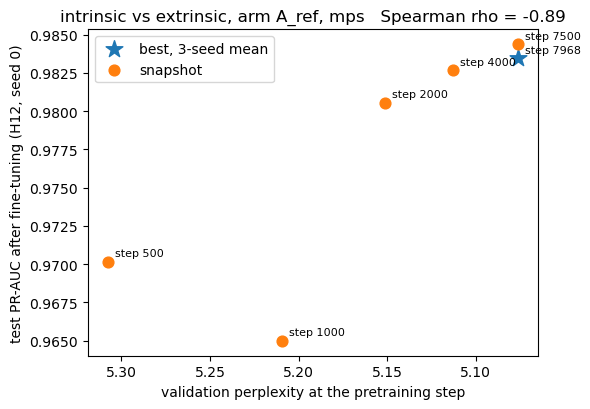

Spearman rho(perplexity, PR-AUC) over 6 points: -0.89  (-1 would mean lower perplexity always meant higher PR-AUC)


In [5]:
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
full = [s for s in ft if s["snapshot"] is None]
arms = {a: mean_sd([s["test"] for s in full if s["arm"] == a]) for a in ARM_LIST if any(s["arm"] == a for s in full)}
ref = arms.get("A_ref")
atab = pd.DataFrame([{"arm": a, "objective": ARMS[a]["objective"], "n seeds": m["pr_auc"]["n_seeds"],
                      **{k: f"{m[k]['mean']:.4f} +- {m[k]['sd']:.4f}" for k in KEYS},
                      "PR-AUC - A": (m["pr_auc"]["mean"] - ref["pr_auc"]["mean"]) if ref else float("nan"),
                      "in A sd": ((m["pr_auc"]["mean"] - ref["pr_auc"]["mean"]) / max(ref["pr_auc"]["sd"], 1e-9)) if ref else float("nan")} for a, m in arms.items()])
display(atab.style.format({"PR-AUC - A": "{:+.4f}", "in A sd": "{:+.1f}"}).hide(axis="index"))

scatter, rho = pd.DataFrame(columns=["step", "perplexity", "pr_auc", "kind"]), float("nan")
if SNAP_ARM and SNAP_ARM in pre:
    curve = {int(st): float(l) for st, l in pre[SNAP_ARM]["eval_curve"]}
    pts = [{"step": s["snapshot"], "perplexity": float(np.exp(curve[s["snapshot"]])), "pr_auc": s["test"]["pr_auc"], "kind": "snapshot"}
           for s in ft if s["arm"] == SNAP_ARM and s["snapshot"] is not None and s["snapshot"] in curve]
    if SNAP_ARM in arms:
        pts.append({"step": pre[SNAP_ARM]["best_step"], "perplexity": pre[SNAP_ARM]["best_perplexity"], "pr_auc": arms[SNAP_ARM]["pr_auc"]["mean"], "kind": "best, 3-seed mean"})
    scatter = pd.DataFrame(pts, columns=["step", "perplexity", "pr_auc", "kind"]).sort_values("step")
    display(scatter)
    rho = float(spearmanr(scatter["perplexity"], scatter["pr_auc"]).correlation) if len(scatter) > 2 else float("nan")
    fig, ax = plt.subplots(figsize=(6, 4.2))
    for kind, g in scatter.groupby("kind"):
        ax.scatter(g["perplexity"], g["pr_auc"], marker="o" if kind == "snapshot" else "*", s=60 if kind == "snapshot" else 160, label=kind)
    for _, p in scatter.iterrows():
        ax.annotate(f"step {p['step']}", (p["perplexity"], p["pr_auc"]), textcoords="offset points", xytext=(5, 4), fontsize=8)
    ax.set_xlabel("validation perplexity at the pretraining step"); ax.set_ylabel("test PR-AUC after fine-tuning (H12, seed 0)")
    ax.set_title(f"intrinsic vs extrinsic, arm {SNAP_ARM}, {DEV}   Spearman rho = {rho:.2f}"); ax.invert_xaxis(); ax.legend()
    plt.tight_layout(); fig.savefig(f"{RES}/06c_{GROUP}_perplexity_vs_prauc.png", dpi=120); plt.show()
    print(f"Spearman rho(perplexity, PR-AUC) over {len(scatter)} points: {rho:.2f}  (-1 would mean lower perplexity always meant higher PR-AUC)")

## Save 06c_objective.json

In [6]:
out = {"group": GROUP, "pretrain": pre, "finetune_runs": ft, "arms": arms, "scatter": scatter.to_dict(orient="records"), "spearman_rho": rho, "epochs": EPOCHS, "runtime": describe()}
with open(f"{RES}/06c_{GROUP}.json", "w") as f:
    json.dump(out, f, indent=2, default=float)
print(f"saved 06c_{GROUP}.json:", list(out))

saved 06c_objective.json: ['group', 'pretrain', 'finetune_runs', 'arms', 'scatter', 'spearman_rho', 'epochs', 'runtime']


## What to read off the numbers

- Arms against A, in A's seed sd: a difference under about 2 sd is a tie at three seeds; say so. Tokenizer group: WF's "data shape" claim predicts that linear amount bins (B) hurt, since most rows land in one or two bins (02's figure); C (no time gap) may tie, as step 5 found the rhythm features unimportant on Sparkov. Objective group: perplexities are not comparable (D's is over masked positions); the per-field accuracy gains and the fine-tuned PR-AUC are. If D is close, the talks' disagreement does not matter at this scale; if D is clearly behind, WF's decoder choice held here.
- Scatter (objective group): the early snapshots will have high perplexity and low PR-AUC, so some correlation is guaranteed; the question is the late part. If the last two or three snapshots sit at nearly the same PR-AUC while perplexity still falls, that is Wealthsimple's point: intrinsic metrics stop predicting downstream value before training stops improving them.
- Every run json carries `runtime`; the report's tables state which machine produced each number. A appears in both groups, trained on whichever machine ran that group; the two A results are a second cross-machine data point next to 06b's G3, not a number to average.

## Push results and this notebook back to GitHub

In [7]:
import shutil, glob, os, json
os.makedirs("results/metrics", exist_ok=True); os.makedirs("results/figures", exist_ok=True)
for f in glob.glob(f"{ROOT}/results/*.json"):
    shutil.copy(f, "results/metrics/")
for f in glob.glob(f"{ROOT}/results/*.png"):
    shutil.copy(f, "results/figures/")
if on_colab():
    def same_code(a, b):   # a Drive notebook may be copied back only if its code cells equal the repo version
        cells = lambda p: ["".join(c["source"]) for c in json.load(open(p))["cells"] if c["cell_type"] == "code"]
        return cells(a) == cells(b)
    for f in glob.glob(f"{ROOT}/notebooks/*.ipynb"):   # outputs are kept so GitHub shows them
        repo = f"notebooks/{os.path.basename(f)}"
        if not os.path.exists(repo) or same_code(f, repo):
            shutil.copy(f, repo)
        else:
            print("STALE, not copied:", os.path.basename(f), "-> delete it from Drive and rerun the setup cell")
    try: name, email = userdata.get("GIT_NAME"), userdata.get("GIT_EMAIL")   # commit identity from Colab secrets, never from the notebook
    except Exception: name = email = ""
    if name and email and tok:
        !git config user.name "{name}" && git config user.email "{email}"
        !git add results notebooks && git commit -q -m "results and notebooks from Colab" && git pull --rebase -q && git push -q   # another notebook may have pushed meanwhile; the files are disjoint
        !git log --oneline | head -1
    else:
        print("not committed: set GIT_NAME, GIT_EMAIL and GH_TOKEN (Contents: read and write on your repo) in Colab secrets to push from Colab")
else:
    print("laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal")
    !git status --short results notebooks

laptop: results copied into results/; this notebook file already is the repo copy; commit from the terminal
 M notebooks/06c_objective.ipynb
 M notebooks/06c_tokenizer.ipynb
?? results/figures/06c_objective_perplexity_vs_prauc.png
?? results/metrics/06c_objective.json
?? results/metrics/06c_objective_A_ref_seed0.json
?? results/metrics/06c_objective_A_ref_seed1.json
?? results/metrics/06c_objective_A_ref_seed2.json
?? results/metrics/06c_objective_A_ref_snap1000_seed0.json
?? results/metrics/06c_objective_A_ref_snap2000_seed0.json
?? results/metrics/06c_objective_A_ref_snap4000_seed0.json
?? results/metrics/06c_objective_A_ref_snap500_seed0.json
?? results/metrics/06c_objective_A_ref_snap7500_seed0.json
?? results/metrics/06c_objective_D_mlm_seed0.json
?? results/metrics/06c_objective_D_mlm_seed1.json
?? results/metrics/06c_objective_D_mlm_seed2.json
?? results/metrics/06c_objective_pretrain_A_ref.json
?? results/metrics/06c_objective_pretrain_D_mlm.json
?? results/metrics/06c_tokenize

In [8]:
if on_colab():
    drive.flush_and_unmount()